# Librerías 

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score,roc_curve,auc,confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

# Carga dataset para exploración 

In [7]:
churn = pd.read_excel("Telco_customer_churn.xlsx")
churn

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,2569-WGERO,1,United States,California,Landers,92285,"34.341737, -116.539416",34.341737,-116.539416,Female,...,Two year,Yes,Bank transfer (automatic),21.15,1419.4,No,0,45,5306,NaN
7039,6840-RESVB,1,United States,California,Adelanto,92301,"34.667815, -117.536183",34.667815,-117.536183,Male,...,One year,Yes,Mailed check,84.80,1990.5,No,0,59,2140,NaN
7040,2234-XADUH,1,United States,California,Amboy,92304,"34.559882, -115.637164",34.559882,-115.637164,Female,...,One year,Yes,Credit card (automatic),103.20,7362.9,No,0,71,5560,NaN
7041,4801-JZAZL,1,United States,California,Angelus Oaks,92305,"34.1678, -116.86433",34.167800,-116.864330,Female,...,Month-to-month,Yes,Electronic check,29.60,346.45,No,0,59,2793,NaN


In [8]:
print(churn.shape)

(7043, 33)


Descripción: Cada fila representa un cliente diferente (hay 7043) y cada columna hace referencia tanto a características personales como a características con respecto a la compañía.

# Análisis de tipos de dato

In [9]:
churn.dtypes

CustomerID            object
Count                  int64
Country               object
State                 object
City                  object
Zip Code               int64
Lat Long              object
Latitude             float64
Longitude            float64
Gender                object
Senior Citizen        object
Partner               object
Dependents            object
Tenure Months          int64
Phone Service         object
Multiple Lines        object
Internet Service      object
Online Security       object
Online Backup         object
Device Protection     object
Tech Support          object
Streaming TV          object
Streaming Movies      object
Contract              object
Paperless Billing     object
Payment Method        object
Monthly Charges      float64
Total Charges         object
Churn Label           object
Churn Value            int64
Churn Score            int64
CLTV                   int64
Churn Reason          object
dtype: object

-------------------------------------------------------------------------------------------------------------------------
La columna total Charges debería ser de tipo float, el problema es que si cambiamos el tipo da el siguiente error:

churn['Total Charges'] = churn['Total Charges'].astype(float)

ValueError: could not convert string to float: ' '

Eso significa que hay espacios que imposibilitan el cambio de tipo al float, por ello reemplazaremos los espacios por na y luego los analizaremos


In [10]:
espacios_en_blanco = churn[churn['Total Charges'] == ' ']
espacios_en_blanco

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
2234,4472-LVYGI,1,United States,California,San Bernardino,92408,"34.084909, -117.258107",34.084909,-117.258107,Female,...,Two year,Yes,Bank transfer (automatic),52.55,,No,0,36,2578,NaN
2438,3115-CZMZD,1,United States,California,Independence,93526,"36.869584, -118.189241",36.869584,-118.189241,Male,...,Two year,No,Mailed check,20.25,,No,0,68,5504,NaN
2568,5709-LVOEQ,1,United States,California,San Mateo,94401,"37.590421, -122.306467",37.590421,-122.306467,Female,...,Two year,No,Mailed check,80.85,,No,0,45,2048,NaN
2667,4367-NUYAO,1,United States,California,Cupertino,95014,"37.306612, -122.080621",37.306612,-122.080621,Male,...,Two year,No,Mailed check,25.75,,No,0,48,4950,NaN
2856,1371-DWPAZ,1,United States,California,Redcrest,95569,"40.363446, -123.835041",40.363446,-123.835041,Female,...,Two year,No,Credit card (automatic),56.05,,No,0,30,4740,NaN
4331,7644-OMVMY,1,United States,California,Los Angeles,90029,"34.089953, -118.294824",34.089953,-118.294824,Male,...,Two year,No,Mailed check,19.85,,No,0,53,2019,NaN
4687,3213-VVOLG,1,United States,California,Sun City,92585,"33.739412, -117.173334",33.739412,-117.173334,Male,...,Two year,No,Mailed check,25.35,,No,0,49,2299,NaN
5104,2520-SGTTA,1,United States,California,Ben Lomond,95005,"37.078873, -122.090386",37.078873,-122.090386,Female,...,Two year,No,Mailed check,20.00,,No,0,27,3763,NaN
5719,2923-ARZLG,1,United States,California,La Verne,91750,"34.144703, -117.770299",34.144703,-117.770299,Male,...,One year,Yes,Mailed check,19.70,,No,0,69,4890,NaN
6772,4075-WKNIU,1,United States,California,Bell,90201,"33.970343, -118.171368",33.970343,-118.171368,Female,...,Two year,No,Mailed check,73.35,,No,0,44,2342,NaN


In [11]:
churn['Total Charges'] = churn['Total Charges'].replace(' ', np.nan)

# Convierte la columna a float. Ahora ya no dará error.
churn['Total Charges'] = churn['Total Charges'].astype(float)

C:\Users\jorge\AppData\Local\Temp\ipykernel_1860\3810830123.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  churn['Total Charges'] = churn['Total Charges'].replace(' ', np.nan)


In [12]:
churn

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Yes,1,89,5340,Competitor had better devices
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,2569-WGERO,1,United States,California,Landers,92285,"34.341737, -116.539416",34.341737,-116.539416,Female,...,Two year,Yes,Bank transfer (automatic),21.15,1419.40,No,0,45,5306,NaN
7039,6840-RESVB,1,United States,California,Adelanto,92301,"34.667815, -117.536183",34.667815,-117.536183,Male,...,One year,Yes,Mailed check,84.80,1990.50,No,0,59,2140,NaN
7040,2234-XADUH,1,United States,California,Amboy,92304,"34.559882, -115.637164",34.559882,-115.637164,Female,...,One year,Yes,Credit card (automatic),103.20,7362.90,No,0,71,5560,NaN
7041,4801-JZAZL,1,United States,California,Angelus Oaks,92305,"34.1678, -116.86433",34.167800,-116.864330,Female,...,Month-to-month,Yes,Electronic check,29.60,346.45,No,0,59,2793,NaN


# Análisis de nulls

In [13]:
churn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [14]:
print(churn['Churn Value'].value_counts())

Churn Value
0    5174
1    1869
Name: count, dtype: int64


-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Si nos fijamos bien se ve que todas las columnas tienen todos los valores no nulos excepto 'Churn Reason' (la última). Esto tiene sentido porque como podemos comprobar 1869 es el número de valores no nulos y se corresponde con el número de filas que tienen valor 1 (abandono), así que tiene sentido. Vamos a sustituir los nulos entonces por el valor 'se_queda'.  

In [15]:
churn['Churn Reason'] = churn['Churn Reason'].fillna('se_queda')

In [16]:
churn['Churn Reason'].isna().sum()
print(churn["Churn Reason"].value_counts())

Churn Reason
se_queda                                     5174
Attitude of support person                    192
Competitor offered higher download speeds     189
Competitor offered more data                  162
Don't know                                    154
Competitor made better offer                  140
Attitude of service provider                  135
Competitor had better devices                 130
Network reliability                           103
Product dissatisfaction                       102
Price too high                                 98
Service dissatisfaction                        89
Lack of self-service on Website                88
Extra data charges                             57
Moved                                          53
Lack of affordable download/upload speed       44
Long distance charges                          44
Limited range of services                      44
Poor expertise of phone support                20
Poor expertise of online support     

Para atribuir los nulls a la columna de Total Charges primero vamos a ver como se distribuyen sus datos

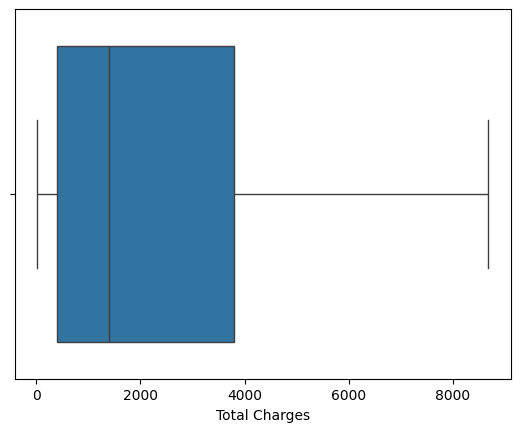

In [17]:
sns.boxplot(data = churn, x=churn['Total Charges'])
plt.show()

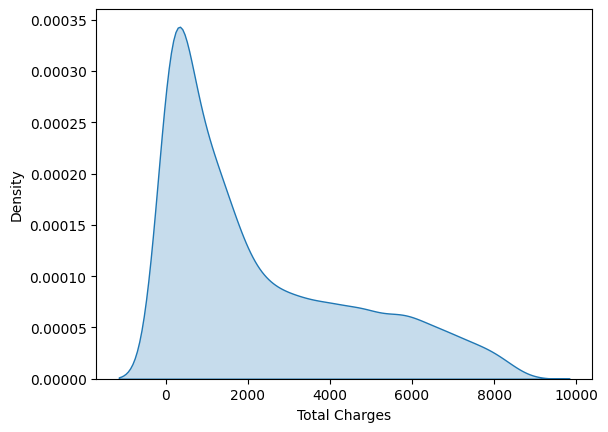

In [18]:
sns.kdeplot(data = churn, x = 'Total Charges', fill = True)
plt.show()

In [19]:
print(churn['Total Charges'].describe())

count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: Total Charges, dtype: float64


Como se puede ver gracias al .describe() y al kdeplot, la media se ve afectada por unos valores altos que estan sesgando la distribución entonces es mejor aplicar la mediana.

In [20]:
mediana_cargos = churn['Total Charges'].median()

In [21]:
churn['Total Charges'].fillna(mediana_cargos, inplace=True)

C:\Users\jorge\AppData\Local\Temp\ipykernel_1860\4195289185.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  churn['Total Charges'].fillna(mediana_cargos, inplace=True)


# Elinimación de columnas innecesarias

In [22]:
print('Países diferentes:')
print(churn['Country'].unique())
print('Estados diferentes:')
print(churn['State'].unique())
print('Ciudades diferentes:')
print(list(churn['City'].unique()))

Países diferentes:
['United States']
Estados diferentes:
['California']
Ciudades diferentes:
['Los Angeles', 'Beverly Hills', 'Huntington Park', 'Lynwood', 'Marina Del Rey', 'Inglewood', 'Santa Monica', 'Torrance', 'Whittier', 'La Habra', 'Pico Rivera', 'Avalon', 'Harbor City', 'Lakewood', 'Los Alamitos', 'San Pedro', 'Carson', 'Long Beach', 'Altadena', 'Monrovia', 'Sierra Madre', 'Tujunga', 'Pasadena', 'Glendale', 'Canoga Park', 'Mission Hills', 'Santa Clarita', 'Sun Valley', 'Stevenson Ranch', 'Panorama City', 'Van Nuys', 'Burbank', 'North Hollywood', 'Covina', 'El Monte', 'La Puente', 'Rowland Heights', 'Ontario', 'Pomona', 'Rosemead', 'San Dimas', 'West Covina', 'Alhambra', 'Alpine', 'Bonita', 'Boulevard', 'Guatay', 'Jacumba', 'Mount Laguna', 'Borrego Springs', 'Carlsbad', 'Del Mar', 'El Cajon', 'Escondido', 'Oceanside', 'Pala', 'Palomar Mountain', 'Pauma Valley', 'Ranchita', 'Valley Center', 'San Diego', 'Indio', 'Indian Wells', 'Palm Desert', 'Desert Hot Springs', 'Holtville', 'N

Podemos usar las columnas geográficas para analizar si hay diferencias entre regiones, sin embargo realmente solo es útil la de "City" y la de 'Longitud' y 'Latitud' por separado, porque la columna de 'State' tiene únicamente el valor California, la de 'Country' solo tiene el valor Estados Unidos y la de 'Lat Lon' se podría utilizar para hacer algún mapa pero se tendría que separar, como la tenemos por separado también la eliminamos. 

In [23]:
churn = churn.drop(columns = ['Count','State','Country','Zip Code', 'Lat Long'])

# Análisis de patrones 

Churn Value
0    0.73463
1    0.26537
Name: proportion, dtype: float64


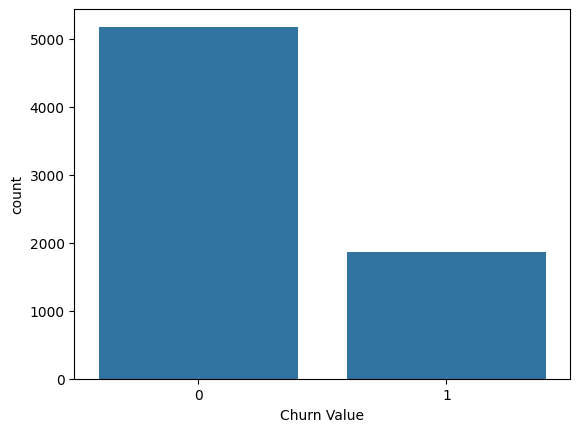

In [24]:
print(churn['Churn Value'].value_counts(normalize=True))

sns.countplot(data = churn, x = churn['Churn Value'])
plt.show()

In [25]:
filtro_se_van = churn[churn['Churn Value']==1]
lista_razones_abandono = list(filtro_se_van['Churn Reason'].unique())
print(f'Hay en total {len(lista_razones_abandono)} razones diferentes de abandono:\n')
# Se ha hecho el filtro para que no se incluya en el bucle 'se_queda' correspondiente a los que no se han ido

numero = 1
for n in lista_razones_abandono:
    print(f'{numero} - {n}')
    numero = numero +1

Hay en total 20 razones diferentes de abandono:

1 - Competitor made better offer
2 - Moved
3 - Competitor had better devices
4 - Competitor offered higher download speeds
5 - Competitor offered more data
6 - Price too high
7 - Product dissatisfaction
8 - Service dissatisfaction
9 - Lack of self-service on Website
10 - Network reliability
11 - Limited range of services
12 - Lack of affordable download/upload speed
13 - Long distance charges
14 - Extra data charges
15 - Don't know
16 - Poor expertise of online support
17 - Poor expertise of phone support
18 - Attitude of service provider
19 - Attitude of support person
20 - Deceased


In [26]:
agrupacion = filtro_se_van.groupby('Churn Reason').agg(recuento = ('CustomerID', 'count')).nlargest(10,columns='recuento').reset_index()
agrupacion

,Churn Reason,recuento
0,Attitude of support person,192
1,Competitor offered higher download speeds,189
2,Competitor offered more data,162
3,Don't know,154
4,Competitor made better offer,140
5,Attitude of service provider,135
6,Competitor had better devices,130
7,Network reliability,103
8,Product dissatisfaction,102
9,Price too high,98


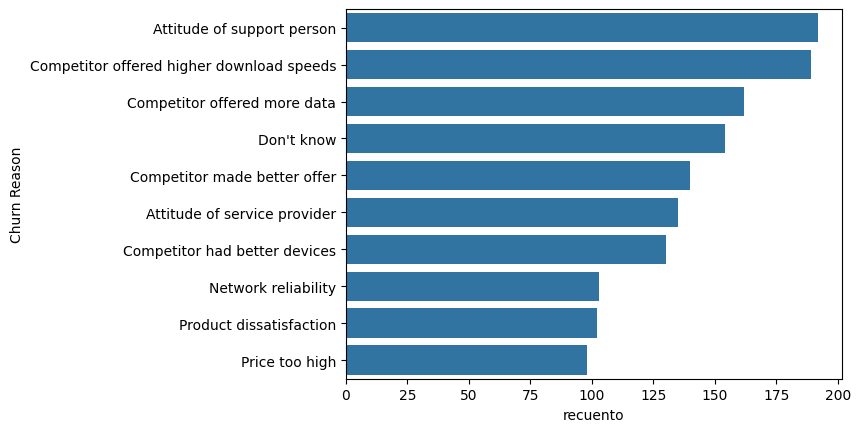

In [27]:
sns.barplot(data = agrupacion, y = 'Churn Reason', x = 'recuento')
plt.show()

In [28]:
recuento_ciudades_con_mas_clientes = churn.groupby(['City']).agg(recuento_clientes = ('CustomerID', 'count')).reset_index().nlargest(20,columns='recuento_clientes')
lista_ciudades = list(recuento_ciudades_con_mas_clientes['City'].unique())
recuento_ciudades_con_mas_clientes

,City,recuento_clientes
562,Los Angeles,305
869,San Diego,150
878,San Jose,112
855,Sacramento,108
872,San Francisco,104
354,Fresno,64
556,Long Beach,60
702,Oakland,52
972,Stockton,44
56,Bakersfield,40


In [29]:
churn_grafico = churn[churn['City'].isin(lista_ciudades)]

Análisis de los clientes que se van y se quedan de las 30 ciudades con mas clientes

<Axes: xlabel='count', ylabel='City'>

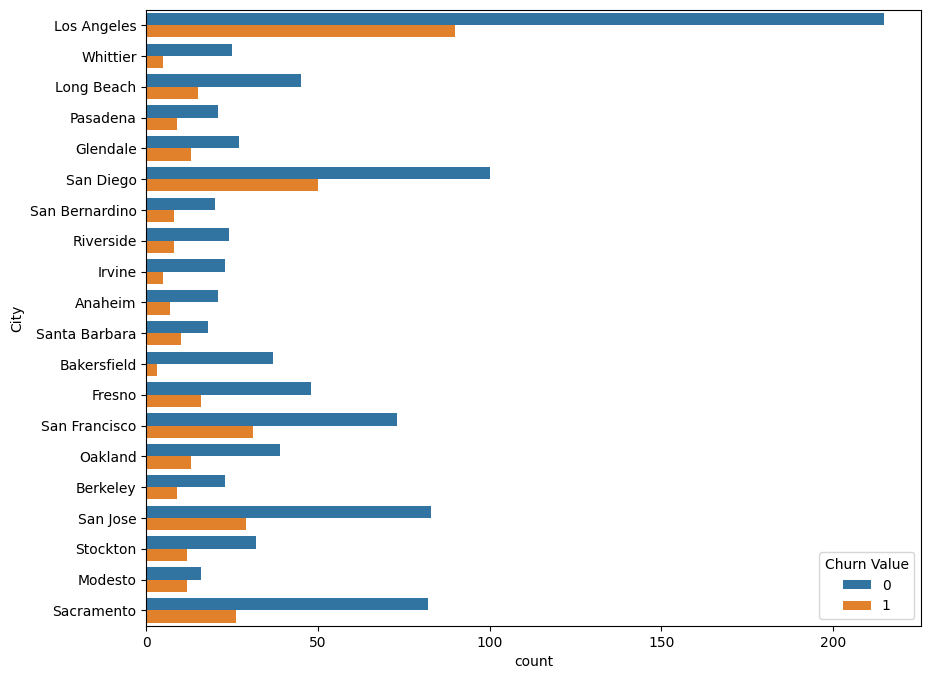

In [30]:
plt.figure(figsize = (10,8))
sns.countplot(data = churn_grafico, y = 'City', hue='Churn Value')
# plt.xticks(rotation = 45)

Análisis de la proporción de abandono dentro de las 20 ciudades con mas clientes 

In [31]:
total = churn.groupby('City').agg(total = ('CustomerID','count')).reset_index()
total

,City,total
0,Acampo,4
1,Acton,4
2,Adelanto,5
3,Adin,4
4,Agoura Hills,5
...,...,...
1124,Yreka,4
1125,Yuba City,8
1126,Yucaipa,4
1127,Yucca Valley,5


In [32]:
clientes_que_se_van = churn[churn['Churn Value'] == 1]

In [33]:
agrupacion_Se_van = clientes_que_se_van.groupby('City').agg(se_van = ('CustomerID','count')).reset_index()
total
agrupacion_Se_van

,City,se_van
0,Acampo,3
1,Adelanto,1
2,Adin,2
3,Agoura Hills,2
4,Aguanga,1
...,...,...
828,Yorkville,1
829,Yosemite National Park,2
830,Yuba City,2
831,Yucaipa,1


In [34]:
total = total.merge(agrupacion_Se_van, how = 'left',left_on='City', right_on = 'City')
total['proporcion'] = (total['se_van']/total['total']) * 100


In [35]:
total = total[total['City'].isin(lista_ciudades)].sort_values(by='proporcion',ascending = False)

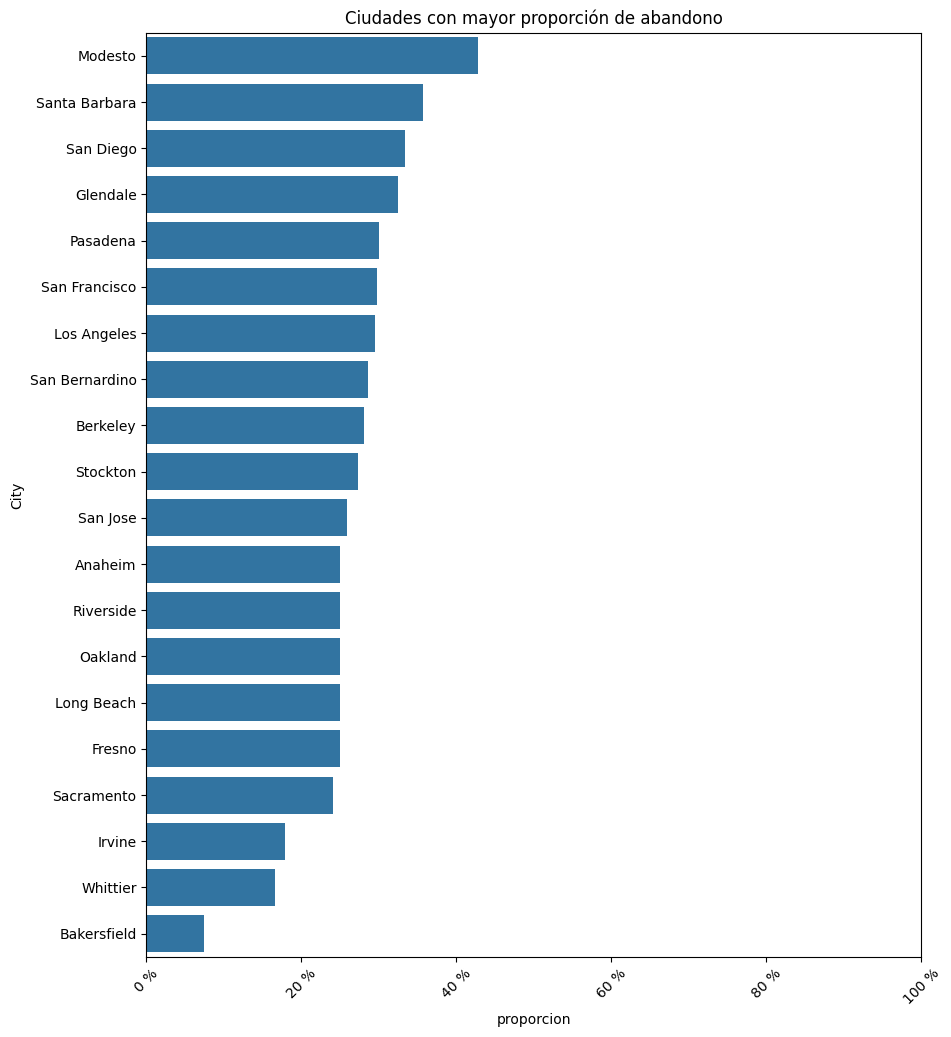

In [36]:
plt.figure(figsize = (10,12))
sns.barplot(data = total, x = 'proporcion', y='City', estimator='sum')
plt.title('Ciudades con mayor proporción de abandono')
plt.xticks([0, 20, 40, 60, 80, 100])
plt.gca().set_xticklabels(["0 %", "20 %", "40 %", "60 %", "80 %", "100 %"])
plt.xticks(rotation = 45)
plt.show()

In [37]:
columas_para_histograma = ['Gender',
       'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges','Churn Score', 'CLTV']

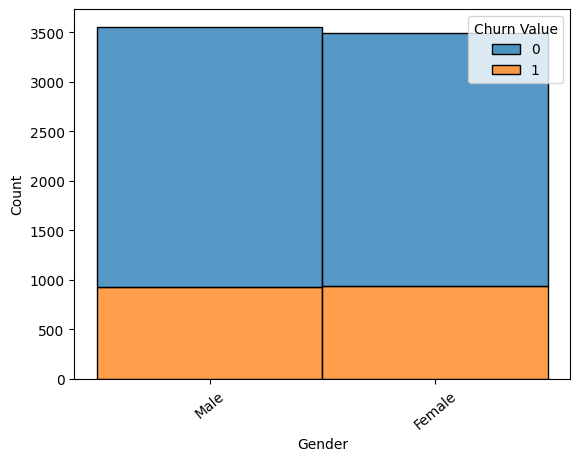

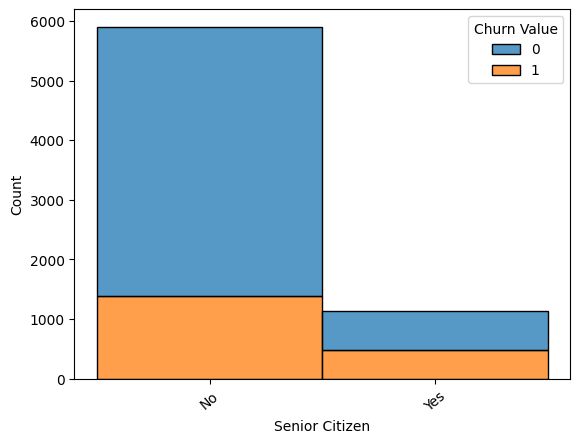

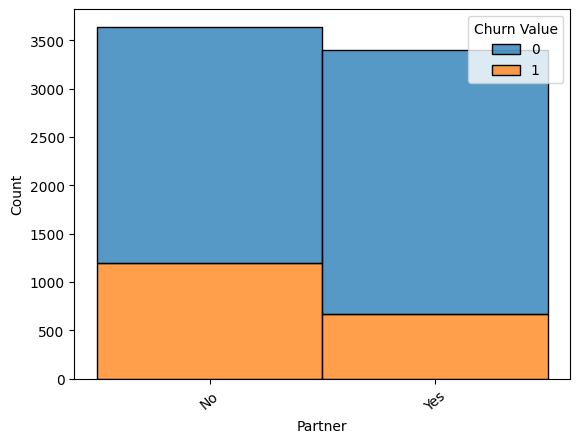

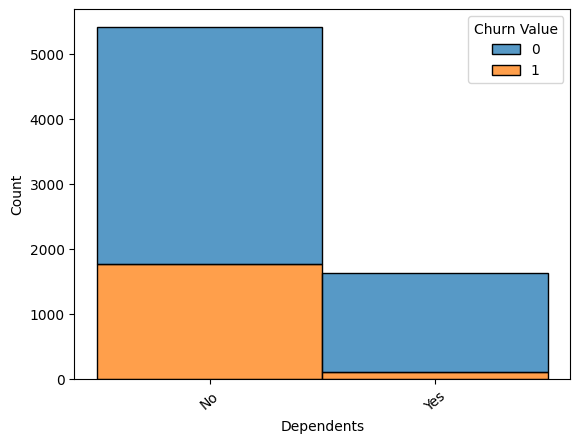

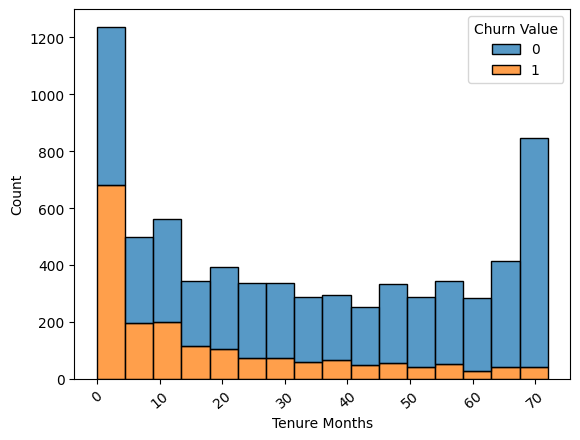

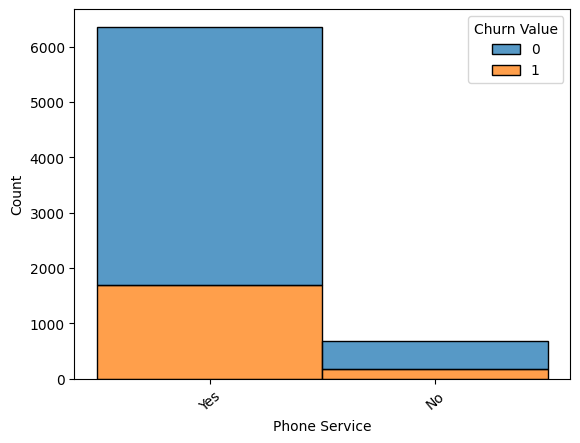

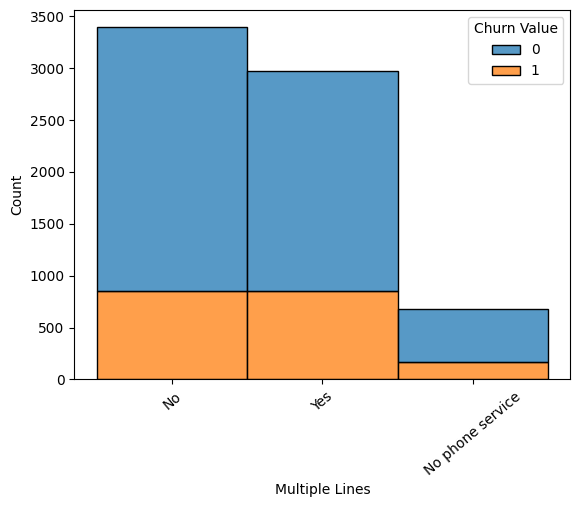

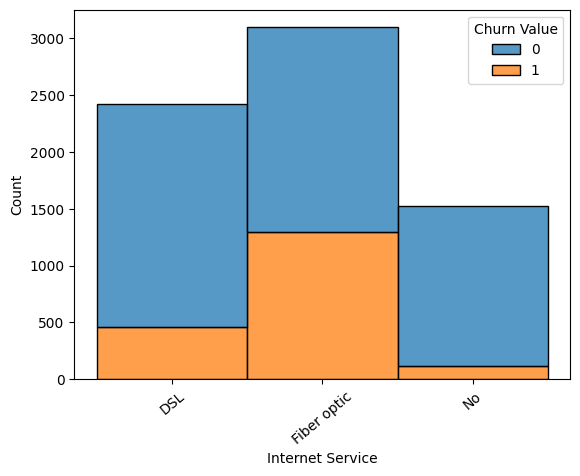

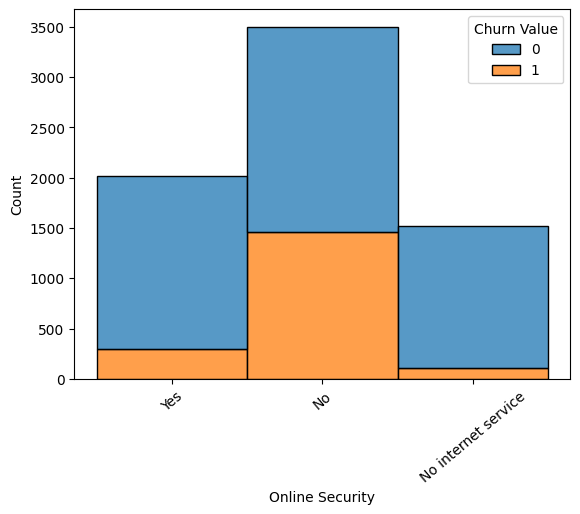

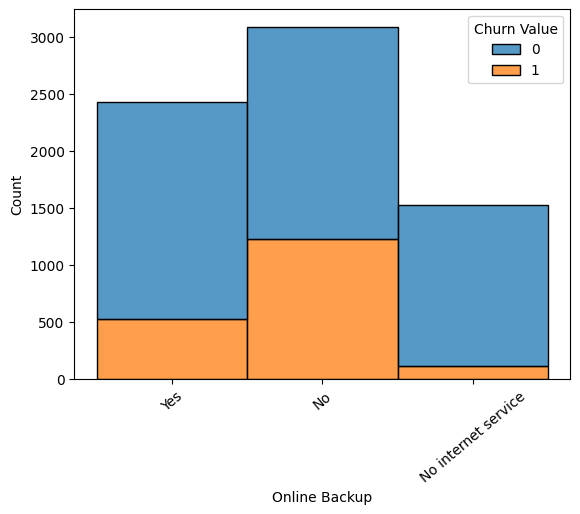

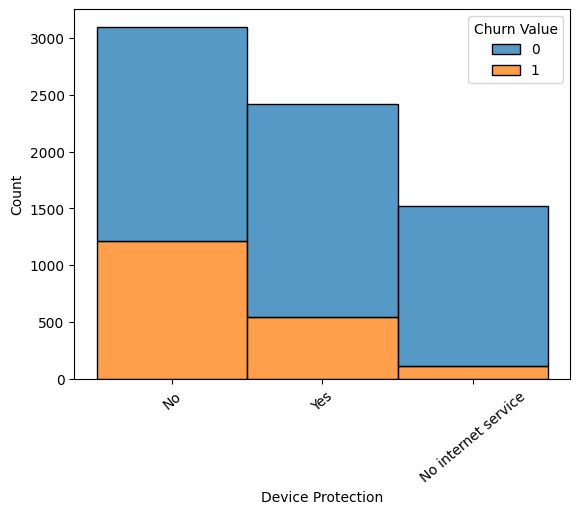

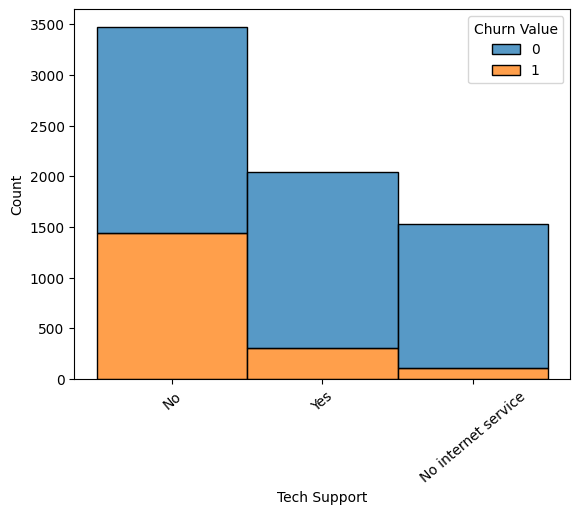

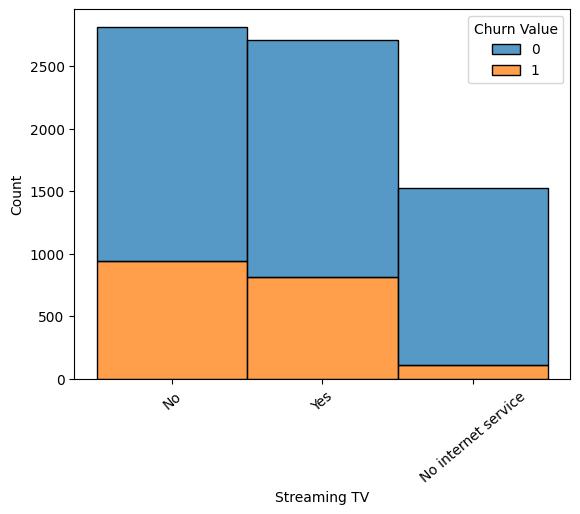

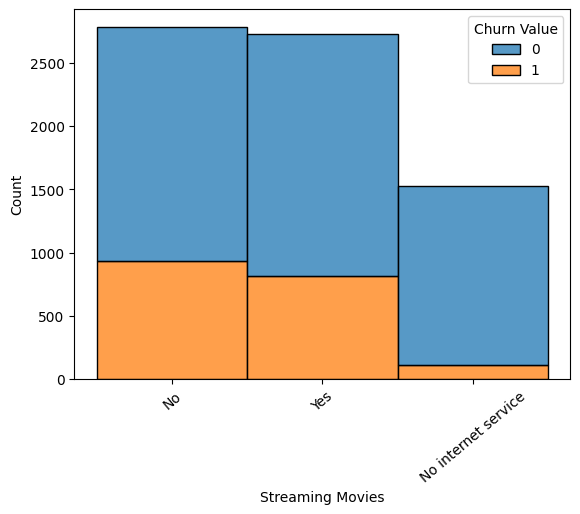

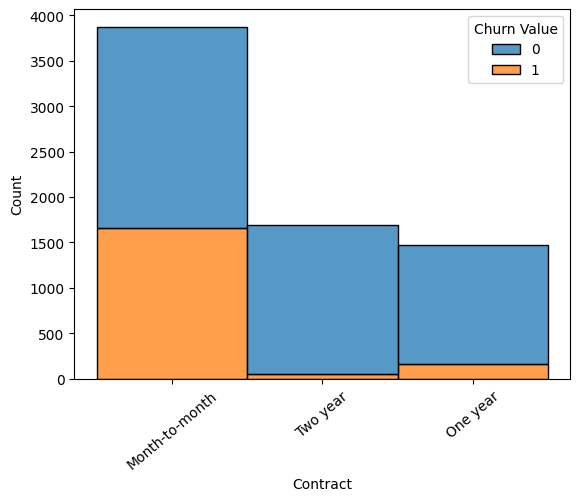

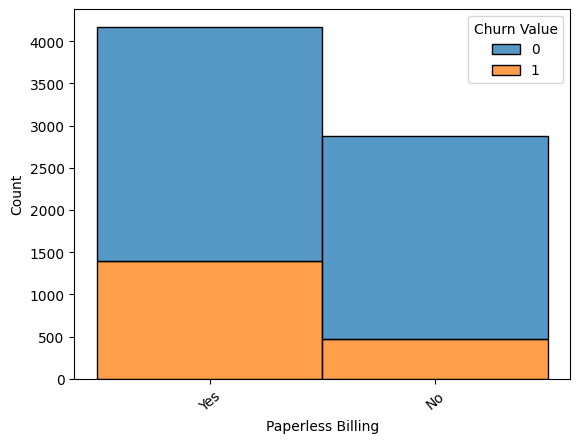

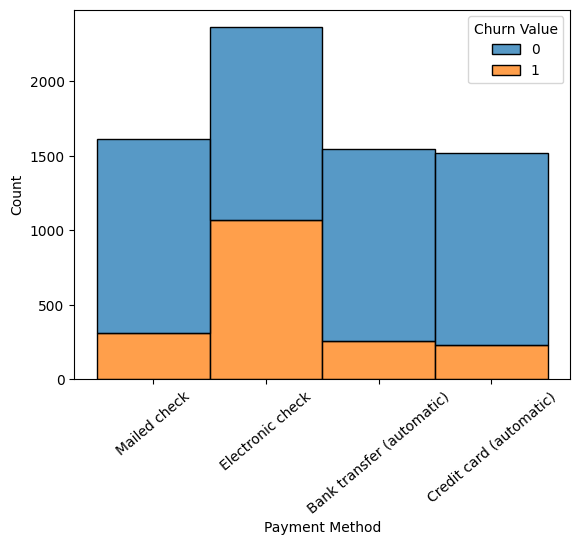

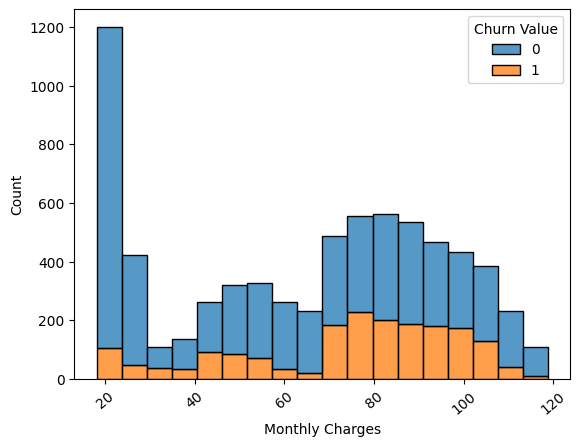

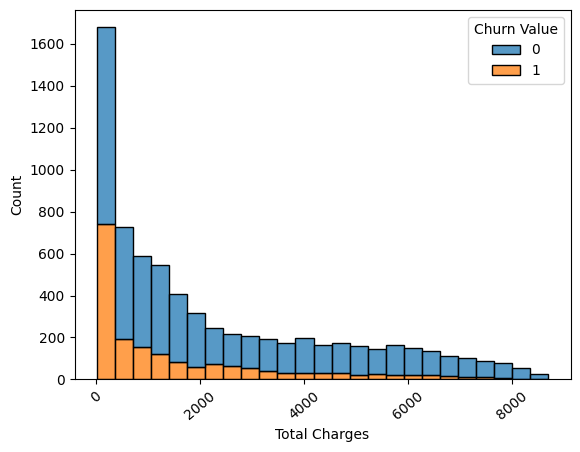

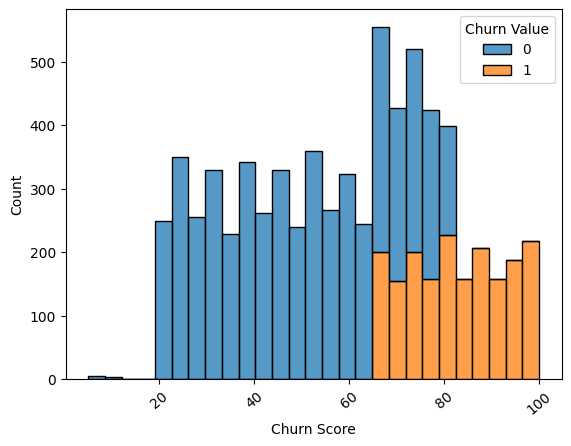

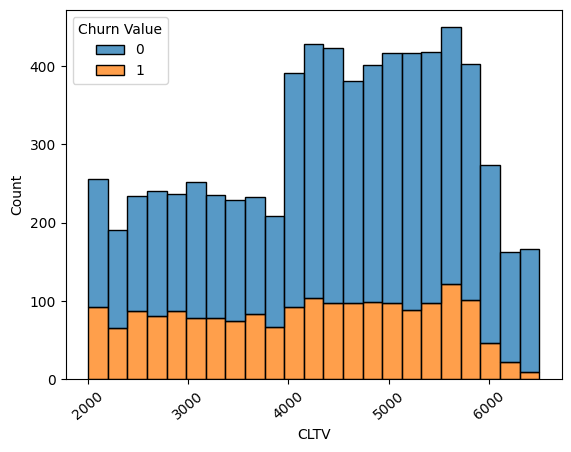

In [38]:
for n in columas_para_histograma:
    sns.histplot(data = churn, x = n, hue = churn['Churn Value'],multiple="stack")
    plt.xticks(rotation = 40)
    plt.show()

In [39]:
churn['Payment Method'].value_counts()

Payment Method
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [40]:
churn["Multiple Lines"] =  churn["Multiple Lines"].replace("No phone service", "No")
churn["Multiple Lines"].value_counts()

columnas_a_transformar_a_no = [
    'Streaming Movies','Streaming TV',
    'Tech Support', 'Device Protection'
    ,'Online Backup', 'Online Security']
for columna in columnas_a_transformar_a_no:
    churn[columna] = churn[columna].replace("No internet service", "No")
    print(f"la columna: '{columna}' \ntiene ahora estos tipos: \n '{churn[columna].value_counts()}'\n")


la columna: 'Streaming Movies' 
tiene ahora estos tipos: 
 'Streaming Movies
No     4311
Yes    2732
Name: count, dtype: int64'

la columna: 'Streaming TV' 
tiene ahora estos tipos: 
 'Streaming TV
No     4336
Yes    2707
Name: count, dtype: int64'

la columna: 'Tech Support' 
tiene ahora estos tipos: 
 'Tech Support
No     4999
Yes    2044
Name: count, dtype: int64'

la columna: 'Device Protection' 
tiene ahora estos tipos: 
 'Device Protection
No     4621
Yes    2422
Name: count, dtype: int64'

la columna: 'Online Backup' 
tiene ahora estos tipos: 
 'Online Backup
No     4614
Yes    2429
Name: count, dtype: int64'

la columna: 'Online Security' 
tiene ahora estos tipos: 
 'Online Security
No     5024
Yes    2019
Name: count, dtype: int64'



In [41]:
churn["Internet Service"].value_counts()

Internet Service
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [42]:
import pandas as pd
y = churn["Churn Label"]
features = [
    "Gender", "Senior Citizen", "Partner",
    "Dependents", "Tenure Months",
    "Phone Service", "Multiple Lines",
    "Internet Service", "Online Security",
    "Online Backup", "Device Protection",
    "Tech Support", "Streaming TV",
    "Streaming Movies", "Contract",
    "Paperless Billing", "Payment Method",
    "Monthly Charges", "Total Charges"
]
X = churn[features].copy()
columnas_a_transformar = X.select_dtypes(include="object").columns

#Transformamos con .cat.codes a categoría con número
for i in columnas_a_transformar:
    X[i] = X[i].astype("category").cat.codes



# X = churn[[""]]

In [43]:
for col in columnas_a_transformar:
    print(f"Columna: '{col}' | Valores únicos codificados: {X[col].unique()}")

Columna: 'Gender' | Valores únicos codificados: [1 0]
Columna: 'Senior Citizen' | Valores únicos codificados: [0 1]
Columna: 'Partner' | Valores únicos codificados: [0 1]
Columna: 'Dependents' | Valores únicos codificados: [0 1]
Columna: 'Phone Service' | Valores únicos codificados: [1 0]
Columna: 'Multiple Lines' | Valores únicos codificados: [0 1]
Columna: 'Internet Service' | Valores únicos codificados: [0 1 2]
Columna: 'Online Security' | Valores únicos codificados: [1 0]
Columna: 'Online Backup' | Valores únicos codificados: [1 0]
Columna: 'Device Protection' | Valores únicos codificados: [0 1]
Columna: 'Tech Support' | Valores únicos codificados: [0 1]
Columna: 'Streaming TV' | Valores únicos codificados: [0 1]
Columna: 'Streaming Movies' | Valores únicos codificados: [0 1]
Columna: 'Contract' | Valores únicos codificados: [0 2 1]
Columna: 'Paperless Billing' | Valores únicos codificados: [1 0]
Columna: 'Payment Method' | Valores únicos codificados: [3 2 0 1]


In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,     
    random_state=42,   
    stratify=y        
)
print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(5282, 19) (1761, 19)
(5282,) (1761,)


In [45]:
Regresion_Logistica = LogisticRegression(random_state = 42, max_iter = 10000)
Regresion_Logistica.fit(X_train, y_train)

y_pred_logistic = Regresion_Logistica.predict(X_test)

y_proba = Regresion_Logistica.predict_proba(X_test)
print(y_proba)



[[0.79732494 0.20267506]
 [0.98097755 0.01902245]
 [0.98045312 0.01954688]
 ...
 [0.8492462  0.1507538 ]
 [0.7655675  0.2344325 ]
 [0.45862051 0.54137949]]


In [46]:
accuracy = accuracy_score(y_test, y_pred_logistic)
print(f"Accuracy:   {accuracy * 100}%")

Accuracy:   81.2038614423623%


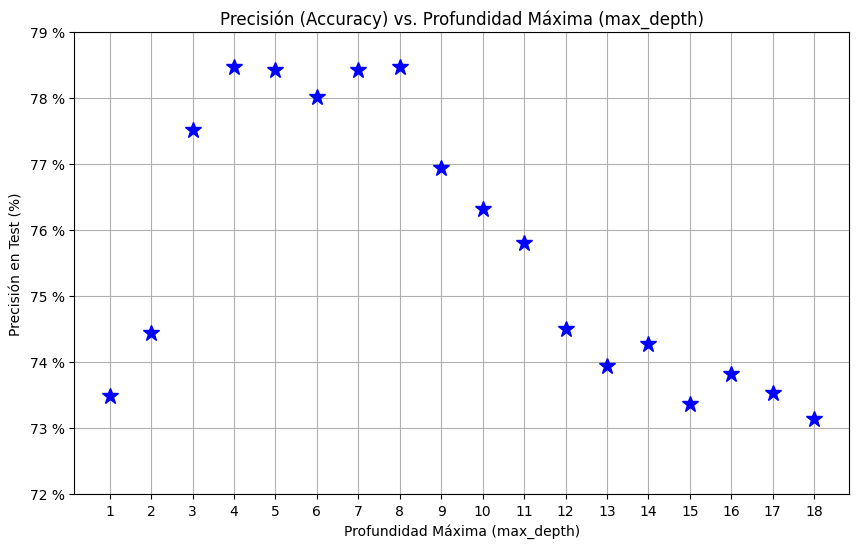

In [65]:

#TEST DE ÁRBOLES CON DISTINTAS max_depth

lista_depth = range(1, 19) 
plt.figure(figsize=(10, 6)) 
depths = []
accuracies = []
for i in lista_depth:
    
    arbol = DecisionTreeClassifier(
        random_state=42,   
        max_depth= i
    )
    arbol.fit(X_train, y_train)
    y_pred_tree = arbol.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred_tree) * 100
    
    plt.plot(i, accuracy, marker='*', linestyle='-', color='b', markersize = 12)
    # print("Arbol con  profundidad: ", i)
    # print(f"ACCURACY:   \t {accuracy}%\n")
    
plt.title('Precisión (Accuracy) vs. Profundidad Máxima (max_depth)')
plt.xlabel('Profundidad Máxima (max_depth)')
plt.ylabel('Precisión en Test (%)')
plt.yticks(range(72,80))
plt.xticks(range(1,19))
plt.grid()
plt.gca().set_yticklabels(["72 %", "73 %", "74 %", "75 %", "76 %", "77 %", "78 %", "79 %"])
plt.show()
